# Height vs Weight: Simple Linear Regression
EDA first, then model building and evaluation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [2]:
df=pd.read_csv('height-weight.csv')

# Exploratory Data Analysis (EDA)
Before fitting the regression, we check the data quality and the shape of each variable:
1. Structure, missing values and duplicates
2. Summary statistics and skewness
3. Distributions (histogram + KDE)
4. Boxplots and outlier detection (IQR and Z-score)
5. Normality check



In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Structure, missing values and duplicates

In [4]:
print("Shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Shape (rows, columns): (23, 2)

Data types:
Weight    int64
Height    int64
dtype: object

Missing values per column:
Weight    0
Height    0
dtype: int64

Duplicate rows: 1


## 2. Summary statistics and skewness

In [5]:
summary = df.describe().T
summary["median"] = df.median()
summary["IQR"] = df.quantile(0.75) - df.quantile(0.25)
summary["CV (%)"] = (df.std() / df.mean() * 100).round(2)   # coefficient of variation
summary["skewness"] = df.skew().round(3)
summary["kurtosis"] = df.kurt().round(3)
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,median,IQR,CV (%),skewness,kurtosis
Weight,23.0,73.83,17.87,45.0,59.0,78.0,86.0,105.0,78.0,27.0,24.21,-0.14,-0.94
Height,23.0,158.39,19.51,120.0,142.5,162.0,175.0,183.0,162.0,32.5,12.32,-0.59,-0.80


In [6]:
def describe_skew(s):
    if abs(s) < 0.5:
        return "approximately symmetric"
    elif abs(s) < 1:
        return "moderately skewed"
    return "highly skewed"

for col in df.columns:
    sk = df[col].skew()
    direction = "right (positive)" if sk > 0 else "left (negative)"
    print(f"{col:7s} skewness = {sk:6.3f} -> {describe_skew(sk)}, tail towards {direction}")

Weight  skewness = -0.136 -> approximately symmetric, tail towards left (negative)
Height  skewness = -0.592 -> moderately skewed, tail towards left (negative)


## 3. Distributions (histogram + KDE)

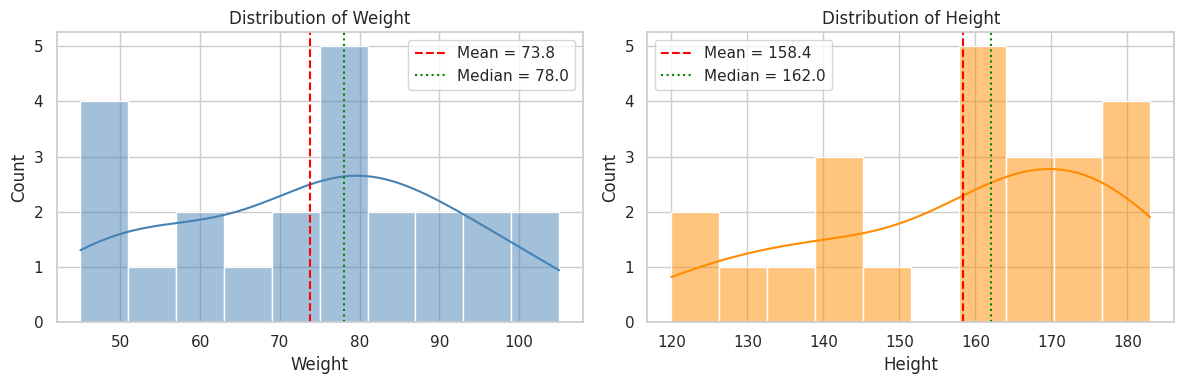

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, color in zip(axes, df.columns, ["steelblue", "darkorange"]):
    sns.histplot(df[col], kde=True, bins=10, color=color, ax=ax)
    ax.axvline(df[col].mean(),   color="red",   linestyle="--", label=f"Mean = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="green", linestyle=":",  label=f"Median = {df[col].median():.1f}")
    ax.set_title(f"Distribution of {col}")
    ax.legend()

plt.tight_layout()
plt.show()

## 4. Boxplots

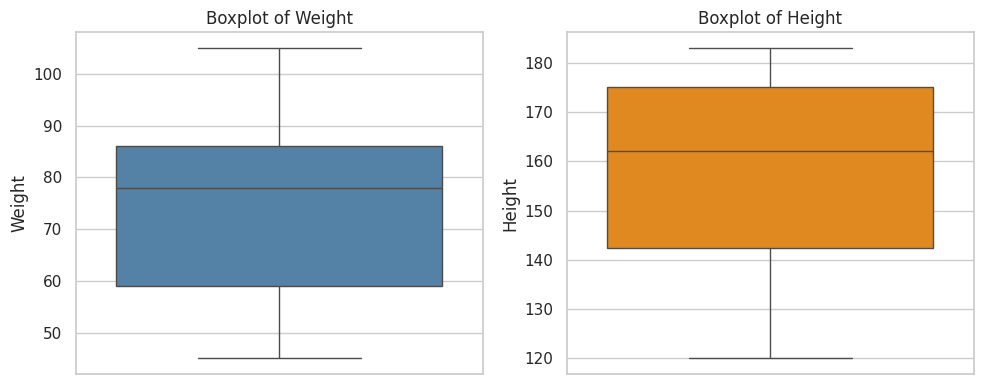

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col, color in zip(axes, df.columns, ["steelblue", "darkorange"]):
    sns.boxplot(y=df[col], color=color, ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

## 5. Outlier detection
- **IQR rule:** a point is an outlier if it is below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`.
- **Z-score rule:** a point is an outlier if `|z| > 3` (with small samples, `|z| > 2.5` is sometimes used).

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < lower) | (s > upper)], lower, upper

rows = []
for col in df.columns:
    out, lo, hi = iqr_outliers(df[col])
    z = np.abs(stats.zscore(df[col]))
    rows.append({
        "Feature": col,
        "IQR lower bound": round(lo, 2),
        "IQR upper bound": round(hi, 2),
        "IQR outliers": len(out),
        "Z-score outliers (|z|>3)": int((z > 3).sum()),
        "Max |z|": round(z.max(), 2),
    })

pd.DataFrame(rows)

,Feature,IQR lower bound,IQR upper bound,IQR outliers,Z-score outliers (|z|>3),Max |z|
0,Weight,18.50,126.50,0,0,1.78
1,Height,93.75,223.75,0,0,2.01


In [10]:
# Inspect the flagged rows (if any)
for col in df.columns:
    out, _, _ = iqr_outliers(df[col])
    if len(out):
        print(f"IQR outliers in {col}:")
        print(df.loc[out.index], "\n")
    else:
        print(f"No IQR outliers in {col}.")

No IQR outliers in Weight.
No IQR outliers in Height.


## 6. Normality check
Linear regression does not require the *features* to be normal, but the **residuals** should be roughly normal. A first look at the raw variables is still useful.

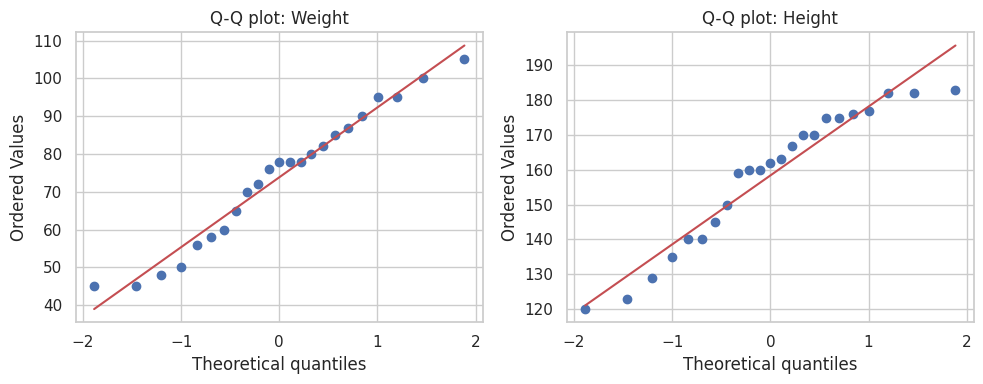

Shapiro-Wilk Weight : W = 0.959, p = 0.449 -> looks normal (alpha = 0.05)
Shapiro-Wilk Height : W = 0.922, p = 0.074 -> looks normal (alpha = 0.05)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, df.columns):
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {col}")
plt.tight_layout()
plt.show()

for col in df.columns:
    stat, p = stats.shapiro(df[col])
    verdict = "looks normal" if p > 0.05 else "deviates from normality"
    print(f"Shapiro-Wilk {col:7s}: W = {stat:.3f}, p = {p:.3f} -> {verdict} (alpha = 0.05)")

## EDA findings
- **Data quality:** 23 rows, 2 numeric columns, no missing values. One duplicate row was found; it is kept because two people can legitimately share the same height and weight, and with only 23 rows every observation matters.
- **Distributions:** Weight is approximately symmetric (skewness -0.14). Height is moderately left-skewed (skewness -0.59), with a longer tail towards shorter heights.
- **Outliers:** neither the IQR rule nor the Z-score rule (max |z| = 2.01) flagged any point, so no data was removed.
- **Normality:** Shapiro-Wilk gives p = 0.449 (Weight) and p = 0.074 (Height), so neither rejects normality at 5%. Height is borderline, and with n = 23 the test has low power, so this is tentative.
- **Takeaway:** the correlation is strong (r = 0.93) and the data is clean, so simple linear regression is appropriate. The small sample size is the main limitation.

In [12]:
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


Text(0, 0.5, 'Height')

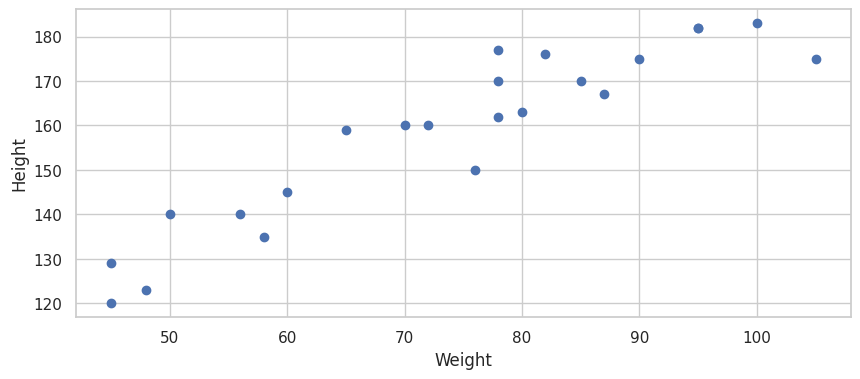

In [13]:
##scatter plot
plt.scatter(df['Weight'],df['Height'])
plt.xlabel("Weight")
plt.ylabel("Height")

In [14]:
## Correlation
df.corr()

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


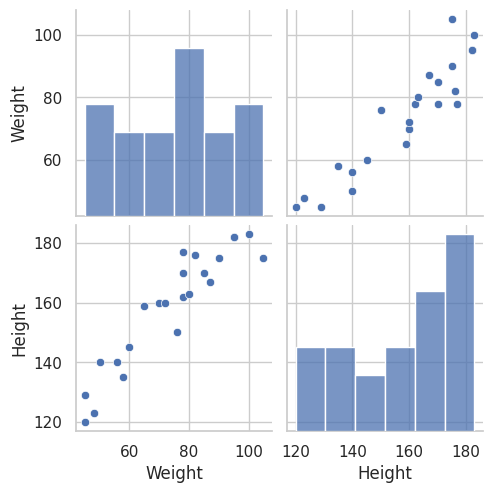

In [15]:
## Seaborn for visualization
import seaborn as sns
sns.pairplot(df)

In [16]:
## Independent and dependent features
X=df[['Weight']] ### independent features should be data frame or 2 dimesnionalarray
y=df['Height'] ## this variiable can be in series or 1d array


In [17]:
X_series=df['Weight']
np.array(X_series).shape

(23,)

In [18]:
np.array(y).shape

(23,)

In [19]:
## Train Test Split
from sklearn.model_selection import train_test_split


In [20]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [21]:
## Standardization
from sklearn.preprocessing import StandardScaler

In [22]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)

In [23]:
X_test=scaler.transform(X_test)

In [24]:
X_test

array([[ 0.33497168],
       [ 0.33497168],
       [-1.6641678 ],
       [ 1.36483141],
       [-0.45256812],
       [ 1.97063125]])

In [25]:
## Apply Simple Linear Regression
from sklearn.linear_model import LinearRegression

In [26]:
regression=LinearRegression(n_jobs=-1)

In [27]:
regression.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",-1
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [28]:
print("Coefficient or slope:",regression.coef_)
print("Intercept:",regression.intercept_)

Coefficient or slope: [17.2982057]
Intercept: 156.47058823529412


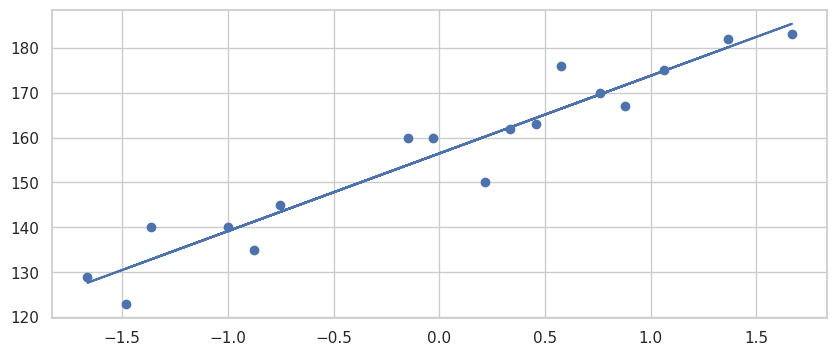

In [29]:
## plot Training data plot best fit line
plt.scatter(X_train,y_train)
plt.plot(X_train,regression.predict(X_train))

### prediction of test data
1. predicted height output= intercept +coef_(Weights)
2. y_pred_test =156.470 + 17.29(X_test)

In [30]:
## Prediction for test data
y_pred=regression.predict(X_test)

In [31]:
## Performance Metrics
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [32]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

114.84069295228699
9.66512588679501
10.716374991212605


## R square 
Formula

**R^2 = 1 - SSR/SST**


R^2	=	coefficient of determination
SSR	=	sum of squares of residuals
SST	=	total sum of squares

In [33]:
from sklearn.metrics import r2_score

In [34]:
score=r2_score(y_test,y_pred)
print(score)

0.7360826717981276


**Adjusted R2 = 1 – [(1-R2)*(n-1)/(n-k-1)]**

where:

R2: The R2 of the model
n: The number of observations
k: The number of predictor variables

In [35]:
#display adjusted R-squared
1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.6701033397476595

In [36]:
## OLS Linear Regression
import statsmodels.api as sm

In [37]:
model=sm.OLS(y_train,X_train).fit()

In [38]:
prediction=model.predict(X_test)
print(prediction)

[  5.79440897   5.79440897 -28.78711691  23.60913442  -7.82861638
  34.08838469]


In [39]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.012
Model:                            OLS   Adj. R-squared (uncentered):             -0.050
Method:                 Least Squares   F-statistic:                             0.1953
Date:                Thu, 15 Oct 2026   Prob (F-statistic):                       0.664
Time:                        10:30:02   Log-Likelihood:                         -110.03
No. Observations:                  17   AIC:                                      222.1
Df Residuals:                      16   BIC:                                      222.9
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [40]:
## Prediction For new data
regression.predict(scaler.transform([[72]]))

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([155.97744705])